## Step 4: Does tumor shape track genetics?

The main question of the project. For each genetic cluster column, it tests whether the tumors in different groups tend to have different shapes.

It runs everything twice, once with the **expert's outlines** (the main analysis) and once with the **model's outlines** (the comparison), so we can see which findings hold up when a computer draws the outlines.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# style settings
font_size = 20
expert_color = "#1d3a8a"
model_color = "#5b2a86"
heatmap_colors = "Purples"

plt.rcParams["font.size"] = font_size
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#d9d9d9"
plt.rcParams["axes.axisbelow"] = True

os.makedirs("figures", exist_ok=True)
print("Done")

Done


### Settings
- **Measures** are the five shapes from step 3. Pieces is left out, since almost every expert outline is a single piece.
- **Min group size** drops any genetic group with fewer patients than this, because a group of 2 or 3 can't tell us much. MethylationCluster group 1, with 4 patients, gets dropped.
- **Significance level** is the cutoff for calling a result real, explained below.

In [2]:
measures = ["Size", "Roundness", "Solidity", "Elongation", "Edge irregularity"]
clusters = ["RNASeqCluster", "MethylationCluster", "miRNACluster", "CNCluster",
            "RPPACluster", "OncosignCluster", "COCCluster"]
min_group_size = 5
significance_level = 0.05

shapes = pd.read_csv("shape_features.csv")
print("Patients:", shapes["Patient"].nunique())
print("Rows (expert + model):", len(shapes))

Patients: 110
Rows (expert + model): 220


### How the test works
For one measure and one cluster column, the **Kruskal-Wallis test** lines up every patient from lowest to highest value (say, from least round to most round), then checks whether one genetic group tends to sit near the top or bottom of that line more than chance would explain. It only uses the order, not the exact values, so a few unusual patients can't throw it off, and it doesn't assume the numbers follow a bell curve.

It gives back a **p-value**, the chance of seeing a difference this big if shape and genetics had nothing to do with each other. A small p-value, like 0.01, means a difference that big would be rare by luck alone.

**Why we adjust the p-values?.** We're running 35 tests (5 measures × 7 clusters). With a 0.05 cutoff, about 1 in 20 tests would come out "significant" by pure luck, even if nothing real were going on. The **Benjamini-Hochberg adjustment** raises the p-values to account for how many tests we ran. A result only counts as significant if its **adjusted p-value** is below 0.05.

**Effect size** shows how big the difference is, on a scale from 0 to 1. It's roughly the share of the spread in the shape measure that the genetic groups explain. Around 0.01 is small, 0.06 is medium, and 0.14 or more is large.

In [3]:
def adjust_p_values(p_values):
    # Benjamini-Hochberg: sort the p-values, scale each one by how many tests ran, keep the order sensible
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    adjusted = np.empty(n)
    running_min = 1.0
    for rank in range(n, 0, -1):
        i = order[rank - 1]
        running_min = min(running_min, p[i] * n / rank)
        adjusted[i] = running_min
    return adjusted


def test_one(data, measure, cluster):
    rows = data[[measure, cluster]].dropna()
    counts = rows[cluster].value_counts()
    keep = counts[counts >= min_group_size].index
    rows = rows[rows[cluster].isin(keep)]
    groups = [g[measure].values for _, g in rows.groupby(cluster)]
    if len(groups) < 2:
        return None
    h, p = stats.kruskal(*groups)
    n = len(rows)
    k = len(groups)
    effect = max(0.0, (h - k + 1) / (n - k))
    return {"Measure": measure, "Cluster": cluster, "Groups": k, "Patients": n,
            "H": h, "p": p, "Effect size": effect}


def run_all(source):
    data = shapes[shapes["Source"] == source]
    results = [test_one(data, m, c) for c in clusters for m in measures]
    results = pd.DataFrame([r for r in results if r is not None])
    results["Adjusted p"] = adjust_p_values(results["p"])
    results["Significant"] = results["Adjusted p"] < significance_level
    results["Source"] = source
    return results

print("Test functions ready")

Test functions ready


### Run the tests

In [4]:
expert_results = run_all("Expert")
model_results = run_all("Model")

all_results = pd.concat([expert_results, model_results])
all_results.to_csv("shape_genetics_results.csv", index=False)
print("Saved shape_genetics_results.csv")
print()

for name, results in [("Expert outlines", expert_results), ("Model outlines", model_results)]:
    print(name)
    print("   Tests run:", len(results))
    print("   Significant after adjustment:", results["Significant"].sum())
    print("   Significant before adjustment (p < 0.05):", (results["p"] < 0.05).sum())
    print()

Saved shape_genetics_results.csv

Expert outlines
   Tests run: 35
   Significant after adjustment: 12
   Significant before adjustment (p < 0.05): 14

Model outlines
   Tests run: 35
   Significant after adjustment: 15
   Significant before adjustment (p < 0.05): 16



### Strongest results with the expert's outlines
Sorted from strongest to weakest. A ✓ in the last column means the result passed the adjusted cutoff.

In [5]:
def show(results, top=12):
    table = results.sort_values("p").head(top).copy()
    table["p"] = table["p"].map(lambda v: f"{v:.4f}")
    table["Adjusted p"] = table["Adjusted p"].map(lambda v: f"{v:.4f}")
    table["Effect size"] = table["Effect size"].map(lambda v: f"{v:.3f}")
    table["H"] = table["H"].map(lambda v: f"{v:.2f}")
    table["Significant"] = table["Significant"].map(lambda v: "✓" if v else "")
    print(table[["Measure", "Cluster", "Groups", "Patients", "H", "p", "Adjusted p", "Effect size", "Significant"]].to_string(index=False))

show(expert_results)

          Measure            Cluster  Groups  Patients     H      p Adjusted p Effect size Significant
         Solidity      RNASeqCluster       4        92 24.45 0.0000     0.0007       0.244           ✓
Edge irregularity      RNASeqCluster       4        92 17.92 0.0005     0.0080       0.170           ✓
             Size        RPPACluster       4        98 15.52 0.0014     0.0148       0.133           ✓
             Size MethylationCluster       4       105 14.98 0.0018     0.0148       0.119           ✓
        Roundness      RNASeqCluster       4        92 14.42 0.0024     0.0148       0.130           ✓
         Solidity          CNCluster       3       108 11.95 0.0025     0.0148       0.095           ✓
             Size          CNCluster       3       108 11.16 0.0038     0.0189       0.087           ✓
         Solidity         COCCluster       3       110 10.82 0.0045     0.0196       0.082           ✓
         Solidity    OncosignCluster       3       105  9.66 0.0080     0

### Figure 1: All 35 tests at a glance
Each square is one test. Darker squares mean stronger evidence that shape differs between that cluster's groups. The number in each square is the adjusted p-value, and squares marked with a ★ passed the 0.05 cutoff.

The left panel uses the expert's outlines and the right panel uses the model's, so you can see whether the same squares light up in both.

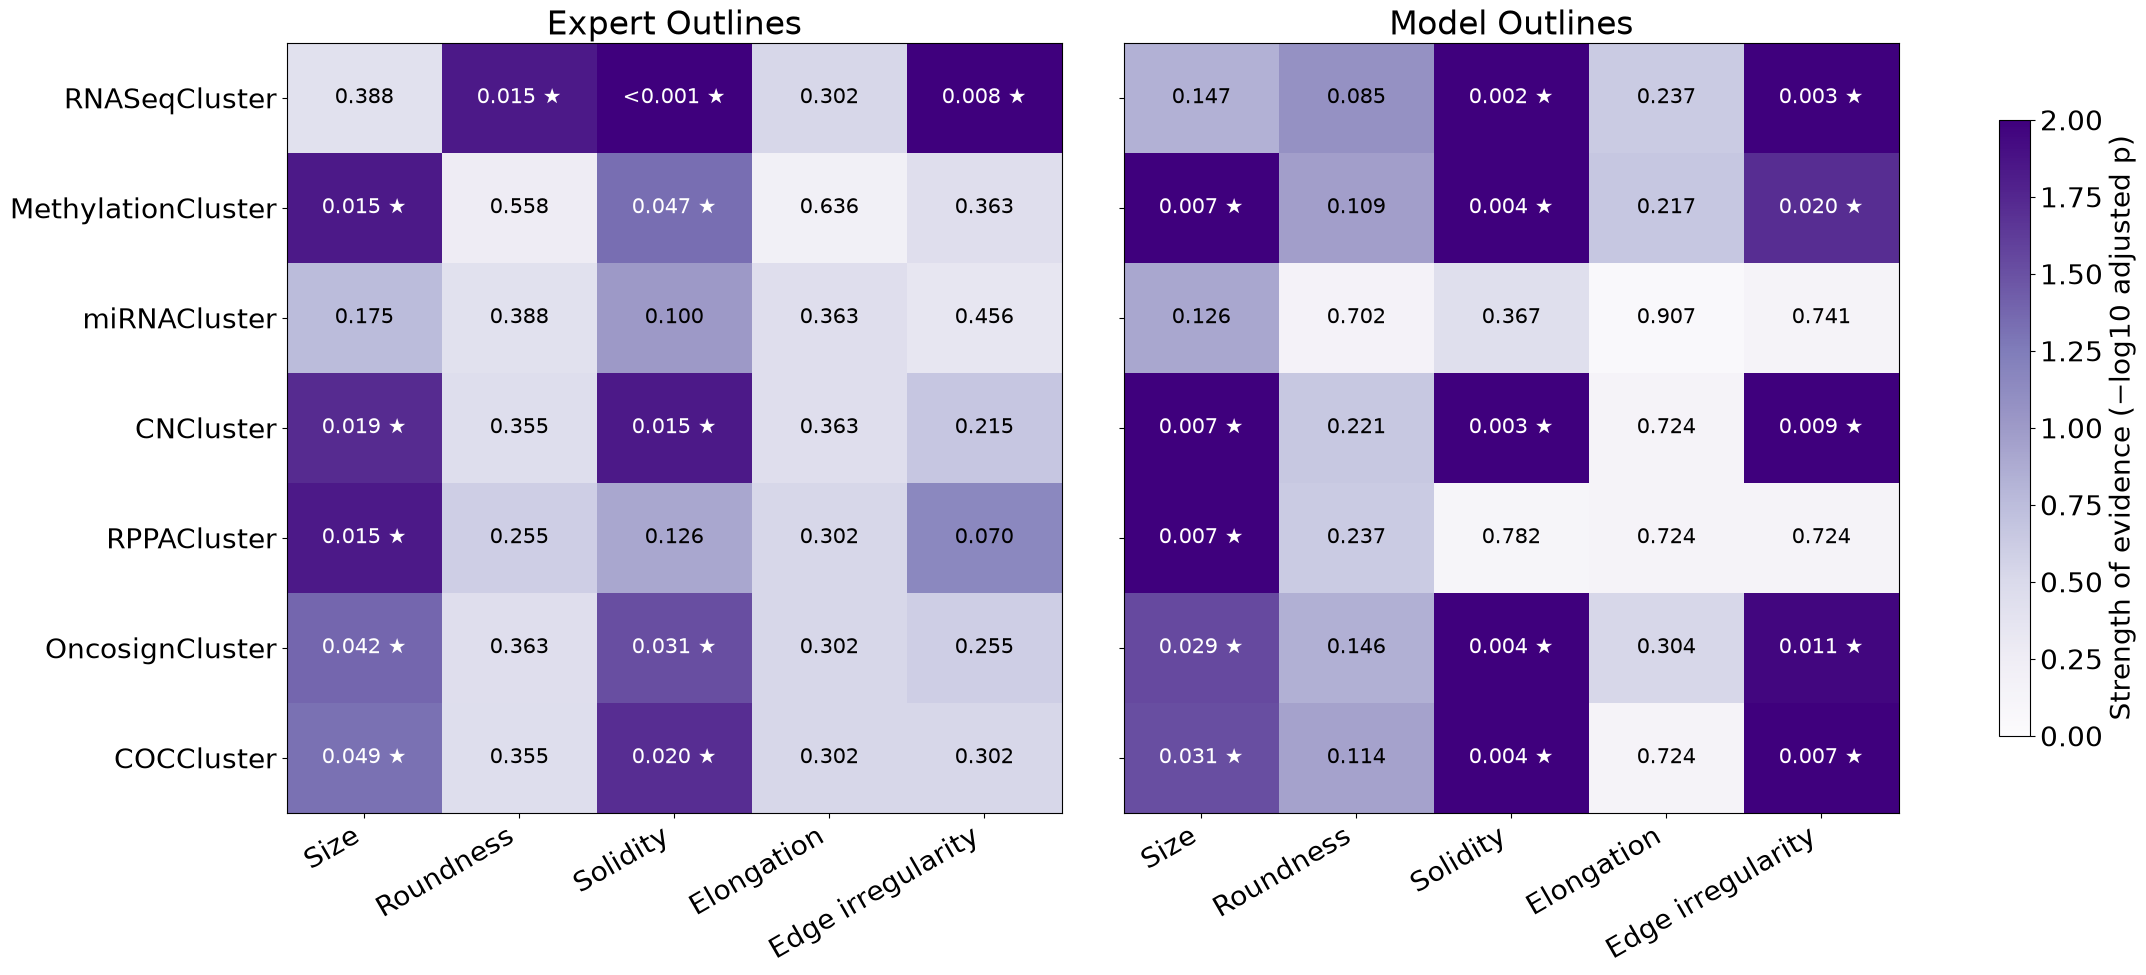

In [6]:
def heat_values(results):
    table = results.pivot(index="Cluster", columns="Measure", values="Adjusted p")
    return table.loc[clusters, measures]


expert_table = heat_values(expert_results)
model_table = heat_values(model_results)
top = max(-np.log10(expert_table.values).max(), -np.log10(model_table.values).max(), 2)

def label(q):
    return "<0.001" if q < 0.001 else f"{q:.3f}"


fig, axes = plt.subplots(1, 2, figsize=(26, 10), gridspec_kw={"wspace": 0.08})
for ax, table, title in [(axes[0], expert_table, "Expert Outlines"), (axes[1], model_table, "Model Outlines")]:
    strength = -np.log10(table.values)
    image = ax.imshow(strength, cmap=heatmap_colors, vmin=0, vmax=top, aspect="auto")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            q = table.values[i, j]
            mark = " ★" if q < significance_level else ""
            color = "white" if strength[i, j] > top * 0.6 else "black"
            ax.text(j, i, f"{label(q)}{mark}", ha="center", va="center", fontsize=15, color=color)
    ax.set_xticks(range(len(measures)))
    ax.set_xticklabels(measures, rotation=30, ha="right")
    ax.set_yticks(range(len(clusters)))
    ax.set_yticklabels(clusters)
    ax.set_title(title)
    ax.grid(False)

axes[1].set_yticklabels([])   # the cluster names are already on the left panel

bar = fig.colorbar(image, ax=axes, shrink=0.8)
bar.set_label("Strength of evidence (−log10 adjusted p)")
plt.savefig(os.path.join("figures", "shape_genetics_heatmap.png"), dpi=200, bbox_inches="tight")
plt.show()

### Figure 2: A closer look at the strongest results
For the top results from the expert's outlines, this shows each patient as a dot, split by genetic group. The black line is each group's median. If one group sits clearly higher or lower than the others, that's the difference the test picked up.

If nothing passed the cutoff, these are still the closest calls, which is worth showing too.

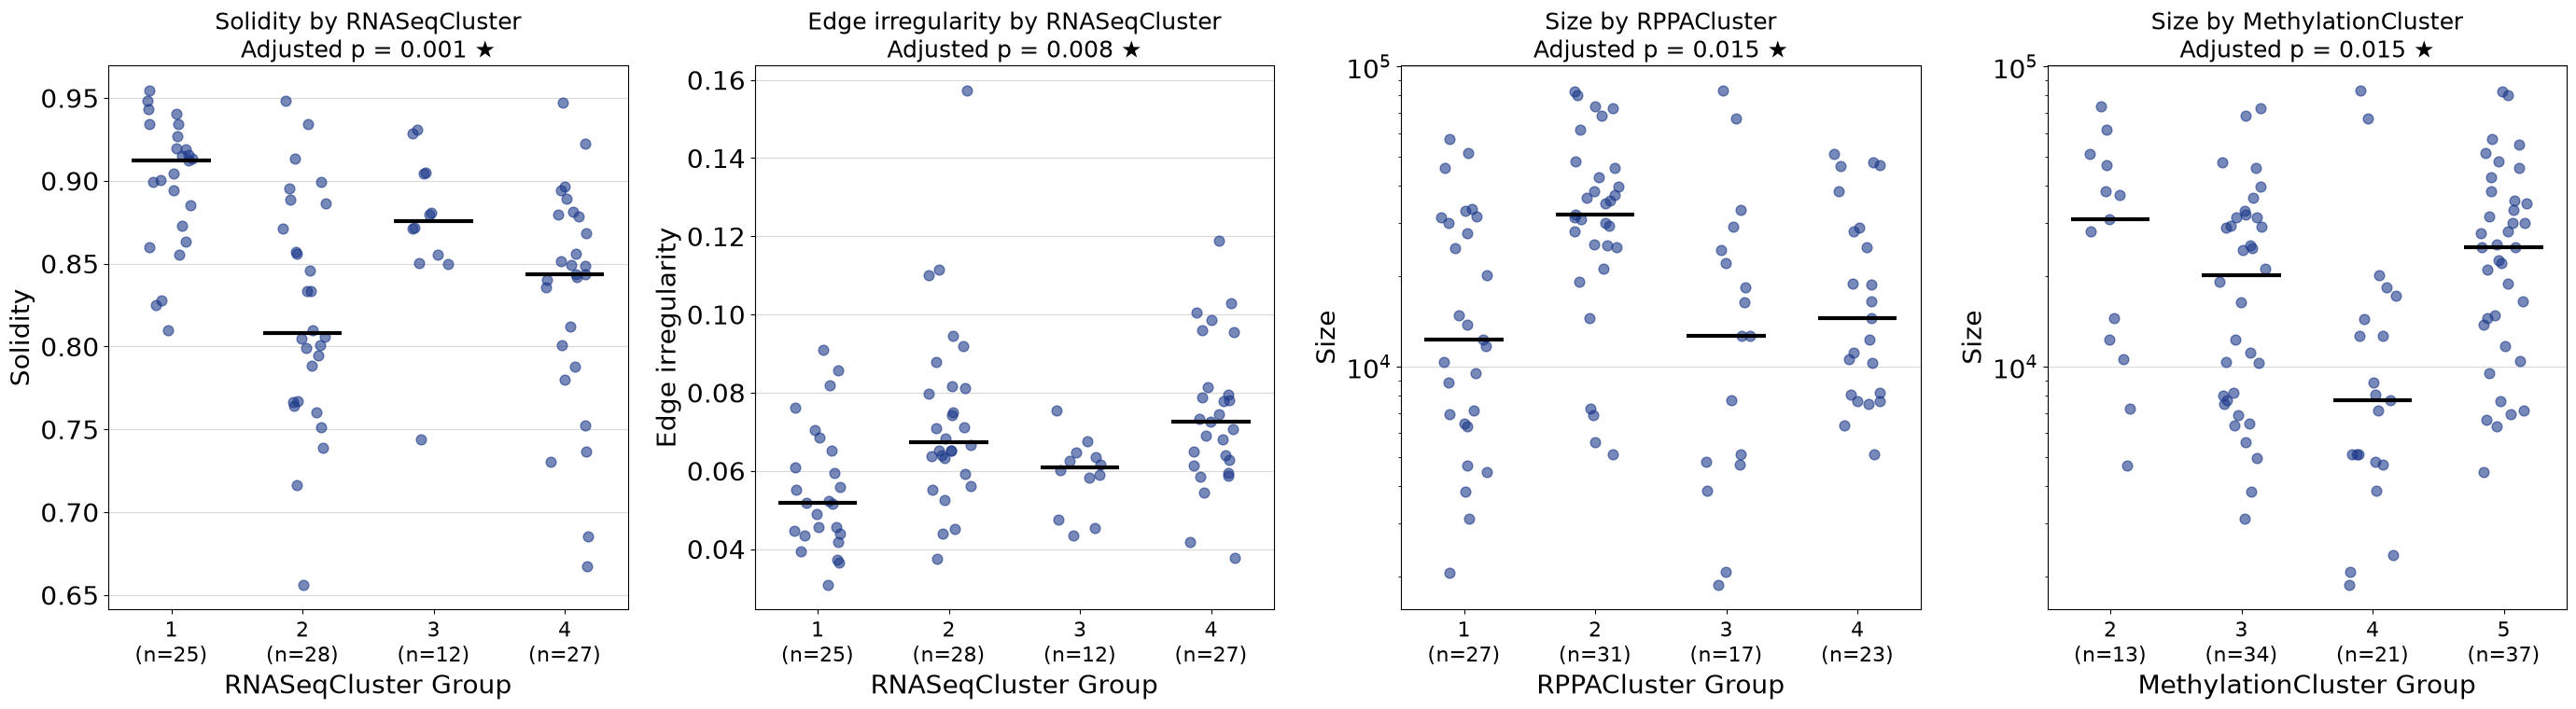

In [7]:
top_results = expert_results.sort_values("p").head(4)
expert_data = shapes[shapes["Source"] == "Expert"]
rng = np.random.default_rng(0)

fig, axes = plt.subplots(1, len(top_results), figsize=(7 * len(top_results), 8))
axes = np.atleast_1d(axes)
for ax, (_, result) in zip(axes, top_results.iterrows()):
    measure, cluster = result["Measure"], result["Cluster"]
    rows = expert_data[[measure, cluster]].dropna()
    counts = rows[cluster].value_counts()
    groups = sorted(counts[counts >= min_group_size].index)

    for x, group in enumerate(groups):
        values = rows.loc[rows[cluster] == group, measure].values
        jitter = rng.uniform(-0.18, 0.18, len(values))
        ax.scatter(np.full(len(values), x) + jitter, values, s=60, color=expert_color, alpha=0.6)
        ax.hlines(np.median(values), x - 0.3, x + 0.3, color="black", linewidth=3)

    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([f"{int(g)}\n(n={counts[g]})" for g in groups], fontsize=16)
    ax.set_xlabel(f"{cluster} Group")
    ax.set_ylabel(measure)
    if measure == "Size":
        ax.set_yscale("log")
    star = " ★" if result["Significant"] else ""
    ax.set_title(f"{measure} by {cluster}\nAdjusted p = {result['Adjusted p']:.3f}{star}", fontsize=18)
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig(os.path.join("figures", "shape_genetics_top_results.png"), dpi=200)
plt.show()

### Group medians for the strongest results
The same comparison as numbers

In [11]:
for _, result in top_results.iterrows():
    measure, cluster = result["Measure"], result["Cluster"]
    rows = expert_data[[measure, cluster]].dropna()
    counts = rows[cluster].value_counts()
    keep = counts[counts >= min_group_size].index
    medians = rows[rows[cluster].isin(keep)].groupby(cluster)[measure].median()
    print(f"{measure} by {cluster} (adjusted p = {result['Adjusted p']:.3f})")
    for group, value in medians.items():
        shown = f"{value:,.0f} pixels" if measure == "Size" else f"{value:.3f}"
        print(f"   Group {int(group)} (n={counts[group]}): median {shown}")
    print()

Solidity by RNASeqCluster (adjusted p = 0.001)
   Group 1 (n=25): median 0.912
   Group 2 (n=28): median 0.808
   Group 3 (n=12): median 0.876
   Group 4 (n=27): median 0.843

Edge irregularity by RNASeqCluster (adjusted p = 0.008)
   Group 1 (n=25): median 0.052
   Group 2 (n=28): median 0.067
   Group 3 (n=12): median 0.061
   Group 4 (n=27): median 0.073

Size by RPPACluster (adjusted p = 0.015)
   Group 1 (n=27): median 12,308 pixels
   Group 2 (n=31): median 32,018 pixels
   Group 3 (n=17): median 12,658 pixels
   Group 4 (n=23): median 14,513 pixels

Size by MethylationCluster (adjusted p = 0.015)
   Group 2 (n=13): median 30,881 pixels
   Group 3 (n=34): median 20,171 pixels
   Group 4 (n=21): median 7,707 pixels
   Group 5 (n=37): median 24,973 pixels



### Do the expert and model outlines lead to the same conclusions?
This lines up every test from both sources. If the model's outlines can stand in for the expert's, the same results should come out strong in both.

In [12]:
compare = expert_results[["Measure", "Cluster", "p", "Adjusted p", "Significant"]].merge(
    model_results[["Measure", "Cluster", "p", "Adjusted p", "Significant"]],
    on=["Measure", "Cluster"], suffixes=(" expert", " model"))

both = (compare["Significant expert"] & compare["Significant model"]).sum()
expert_only = (compare["Significant expert"] & ~compare["Significant model"]).sum()
model_only = (~compare["Significant expert"] & compare["Significant model"]).sum()
rho = stats.spearmanr(compare["p expert"], compare["p model"]).statistic

print("Significant with both outlines:", both)
print("Significant with expert outlines only:", expert_only)
print("Significant with model outlines only:", model_only)
print(f"Agreement on which tests are strongest (Spearman): {rho:.2f}")
print()
print("Strongest model-outline results:")
show(model_results, top=8)

Significant with both outlines: 11
Significant with expert outlines only: 1
Significant with model outlines only: 4
Agreement on which tests are strongest (Spearman): 0.63

Strongest model-outline results:
          Measure            Cluster  Groups  Patients     H      p Adjusted p Effect size Significant
         Solidity      RNASeqCluster       4        92 22.61 0.0000     0.0017       0.223           ✓
         Solidity          CNCluster       3       108 17.40 0.0002     0.0029       0.147           ✓
Edge irregularity      RNASeqCluster       4        92 19.12 0.0003     0.0030       0.183           ✓
         Solidity    OncosignCluster       3       105 15.49 0.0004     0.0037       0.132           ✓
         Solidity MethylationCluster       4       105 17.47 0.0006     0.0037       0.143           ✓
         Solidity         COCCluster       3       110 14.75 0.0006     0.0037       0.119           ✓
             Size          CNCluster       3       108 12.88 0.0016     0

### Figure 3: Expert vs model, test by test
Each dot is one of the 35 tests, placed by its adjusted p-value with the expert's outlines (across) and the model's (up). The dashed lines mark the 0.05 cutoff, so dots in the bottom-left box passed with both kinds of outline. Lower on each axis means stronger evidence, and the axes use a log scale so the small values are easier to tell apart.

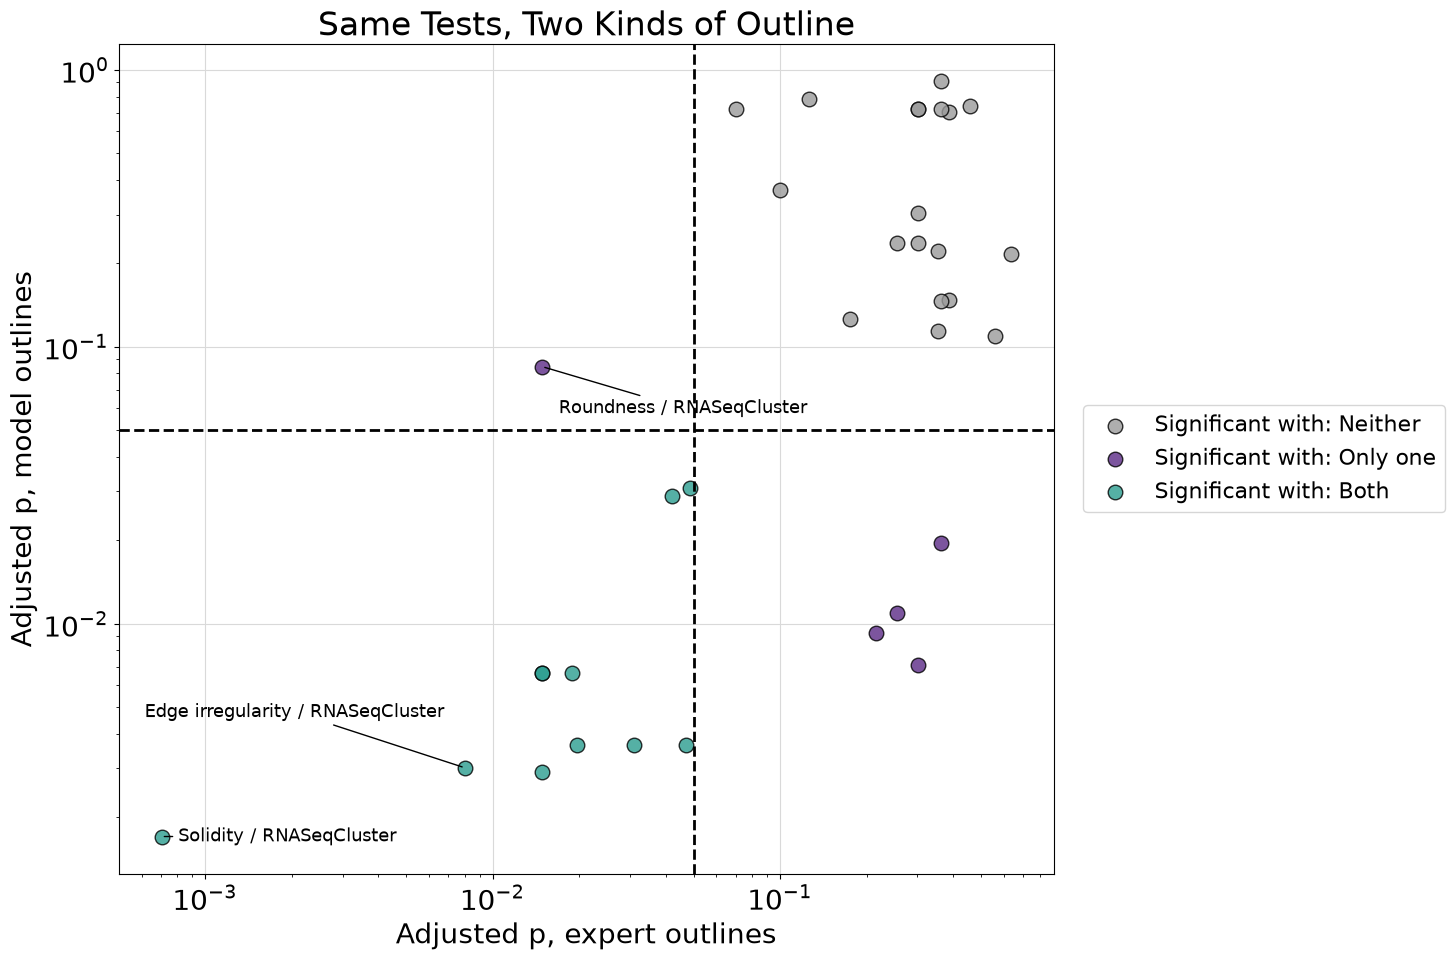

In [13]:
fig, ax = plt.subplots(figsize=(15, 10))
both_sig = compare["Significant expert"] & compare["Significant model"]
one_sig = (compare["Significant expert"] | compare["Significant model"]) & ~both_sig
neither = ~both_sig & ~one_sig

for rows, color, name in [(neither, "#9a9a9a", "Neither"), (one_sig, model_color, "Only one"), (both_sig, "#2a9d8f", "Both")]:
    ax.scatter(compare.loc[rows, "Adjusted p expert"], compare.loc[rows, "Adjusted p model"],
               s=110, color=color, alpha=0.8, edgecolor="black", label=f"Significant with: {name}")

ax.axvline(significance_level, color="black", linestyle="--", linewidth=2)
ax.axhline(significance_level, color="black", linestyle="--", linewidth=2)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Adjusted p, expert outlines")
ax.set_ylabel("Adjusted p, model outlines")
ax.set_title("Same Tests, Two Kinds of Outline")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=16)

# label the 3 strongest expert results, spread out so the labels don't overlap
offsets = [(12, 0, "left"), (-15, 40, "right"), (12, -30, "left")]
for (_, row), (dx, dy, side) in zip(compare.nsmallest(3, "Adjusted p expert").iterrows(), offsets):
    ax.annotate(f"{row['Measure']} / {row['Cluster']}", (row["Adjusted p expert"], row["Adjusted p model"]),
                textcoords="offset points", xytext=(dx, dy), fontsize=13, va="center", ha=side,
                arrowprops={"arrowstyle": "-", "color": "black", "linewidth": 1})

plt.tight_layout()
plt.savefig(os.path.join("figures", "expert_vs_model_pvalues.png"), dpi=200)
plt.show()